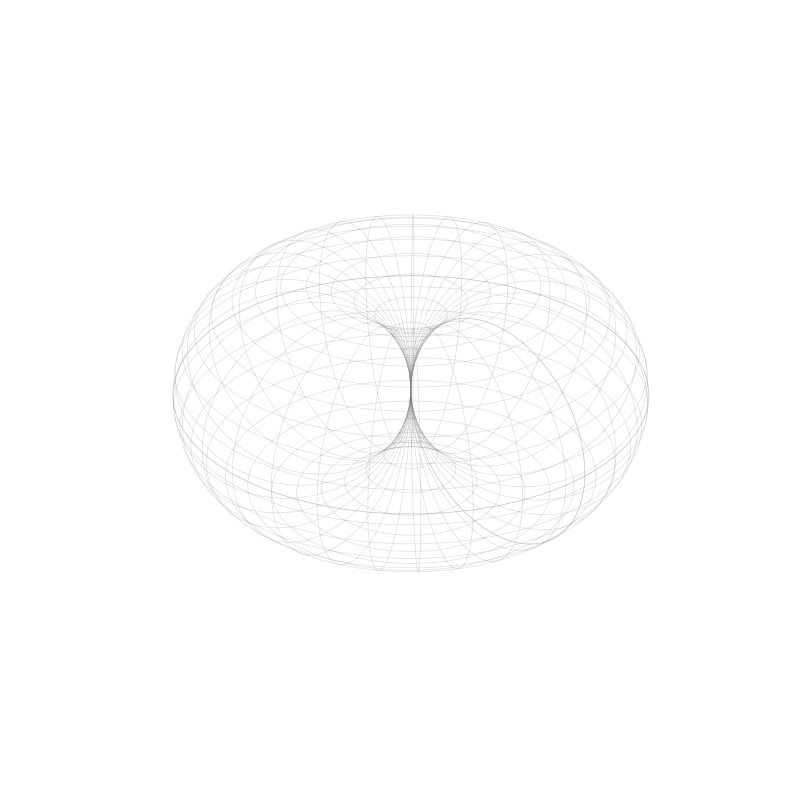

In [1]:
%matplotlib ipympl

import lib.plot as plot
from lib.torus import Torus

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# --- Параметры модели электрона ---
num_points = 400  # Количество точек на волновой нити
num_frames = 120  # Количество кадров для полного зацикленного периода
FPS = 25

# Условие самосопряжения (Рог-тор)
tor = Torus(R = 1.0, r = 1.0)

# --- Инициализация 3D сцены ---
ax = plot.init("Электрон в ОТО: Динамика самосопряженного Horn Torus",
               zoom = 4, elev = 30, azim = 45,
               theme = 'Light')

# Отрисовка сетки рог-тора
tor.plot(ax, 60)

CONST_PI = np.pi
CONST_2PI = CONST_PI * 2

# 2. Инициализация нити волнового фронта
theta_wave = np.linspace(0, 4 * CONST_PI, num_points)

# Спин 1/2, обход 4*pi
theta_wave2 = 0.5 * theta_wave

# Шаг для отрисовки векторов Картана (каждая 15-й точка)
step = 15
theta_quiver = theta_wave[::step]

# Создаем пустые графические объекты, которые будут обновляться в анимации
#wave_line = plot.Segments(ax)
num_ribbon_lines = 5  # Количество линий в ленте
wave_ribbon = []
offsets = np.linspace(-0.1, 0.1, num_ribbon_lines) # Сдвиги фазы

for i in range(num_ribbon_lines):
    line = plot.Segments(ax, cmap='hsv', linewidths=4.0, alpha=0.5)
    wave_ribbon.append(line)

quiver_arrows = [ax.quiver([], [], [], [], [], [], length=0.25, color='blue', normalize=True, pivot='tail') for _ in range(len(theta_quiver))]

# Приращение фазы на фрейм
dphi = CONST_2PI / num_frames

colors0 = np.linspace(0, 1.5, num_points) % 1.0

# 4. Функция обновления кадра анимации
def update(frame):
    global quiver_arrows
    phase = dphi * frame

    # Смещение фазы волнового фронта во времени
    #phi_wave = theta_wave2 - phase

    R = tor.R
    r = tor.r

    phi_base = theta_wave2 - phase

    for idx, offset in enumerate(offsets):
        # Добавляем небольшой сдвиг к каждой линии ленты
        phi_current = phi_base + offset

        rcos_phi = R + r *np.cos(phi_current)
        sin_phi = np.sin(phi_current)

        x_w = rcos_phi * np.cos(theta_wave)
        y_w = rcos_phi * np.sin(theta_wave)
        z_w = r * sin_phi

        points = np.array([x_w, y_w, z_w]).T.reshape(-1, 1, 3)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)

        # Устанавливаем сегменты
        wave_ribbon[idx].set_segments(segments)

        # Циклический сдвиг в зависимости от фазы
        # Преобразуем фазу в количество позиций для сдвига
        shift_amount = int(((CONST_PI + phase - offset) / CONST_2PI) * num_points) % num_points

        # Сдвигаем массив
        colors_shifted = np.roll(colors0, shift_amount)

        wave_ribbon[idx].set_array(colors_shifted)

    # Новые позиции векторов Картана
    phi_quiver = 0.5 * theta_quiver - phase
    x_q = (R + r * np.cos(phi_quiver)) * np.cos(theta_quiver)
    y_q = (R + r * np.cos(phi_quiver)) * np.sin(theta_quiver)
    z_q = r * np.sin(phi_quiver)

    # Направления векторов кручения
    u_q = np.cos(phi_quiver) * np.cos(theta_quiver)
    v_q = np.cos(phi_quiver) * np.sin(theta_quiver)
    w_q = np.sin(phi_quiver)

    # Удаляем старые стрелки Quiver и отрисовываем новые
    for arrow in quiver_arrows:
        arrow.remove()

    quiver_arrows = []
    for i in range(len(theta_quiver)):
        arrow = ax.quiver(x_q[i], y_q[i], z_q[i], u_q[i], v_q[i], w_q[i],
                          length=0.25, color='gold', normalize=True, pivot='tail')
        quiver_arrows.append(arrow)

    return wave_ribbon + quiver_arrows

# Запуск зацикленной анимации
plot.animate(update, num_frames, 1000/FPS)
